# Практическое занятие № 18 — PCA, SVD и влияние снижения размерности на кластеризацию
**ТюмГУ · «Технологии искусственного интеллекта — 1» · 90 минут**

Цель: вручную проверить PCA на матрице 4×2, затем освоить масштабирование, объяснённую дисперсию, восстановление и сравнение кластеризации на Wine (13 признаков) и заказах. **Нельзя** обучать scaler или PCA на holdout и использовать целевые метки для подбора признаков/компонент.

## 1. Вывод PCA на маленьком примере (0–25 мин)
Для центрированной матрицы $X_c$ выборочная ковариация $\Sigma=X_c^T X_c/(n-1)$. Главная ось решает $\max_{\|w\|=1} w^T\Sigma w$; $Z=X_cW_k$. При SVD $X_c=U S V^T$ собственные значения ковариации равны $\lambda_j=s_j^2/(n-1)$.

В примере лекции собственные значения `6` и `2/3`; первая компонента объясняет 90% дисперсии. Знак собственных векторов произволен. Проверьте вычисления самостоятельно.

Python: 3.12.14 ; sklearn: 1.9.1
Среднее: [0. 0.] ; центрированная матрица:
 [[ 2.  1.]
 [ 1.  2.]
 [-1. -2.]
 [-2. -1.]]
Выборочная ковариация Σ:
 [[3.33333333 2.66666667]
 [2.66666667 3.33333333]]
Собственные значения: [6.         0.66666667] ; доли: [0.9 0.1]
Собственные оси NumPy (столбцы, знак условен):
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]
Ручные оси w1, w2 (столбцы):
 [[ 0.70710678  0.70710678]
 [ 0.70710678 -0.70710678]]
Сингулярные значения: [4.24264069 1.41421356] ; S²/(n−1): [6.         0.66666667]
Проекции и восстановление каждой точки:
  point   x1   x2  score_PC1  score_PC2  recovered_x1_PC1  recovered_x2_PC1
     1  2.0  1.0     2.1213     0.7071               1.5               1.5
     2  1.0  2.0     2.1213    -0.7071               1.5               1.5
     3 -1.0 -2.0    -2.1213     0.7071              -1.5              -1.5
     4 -2.0 -1.0    -2.1213    -0.7071              -1.5              -1.5
Ручная доля PC1: 0.8999999999999999 ; RMSE одной PC

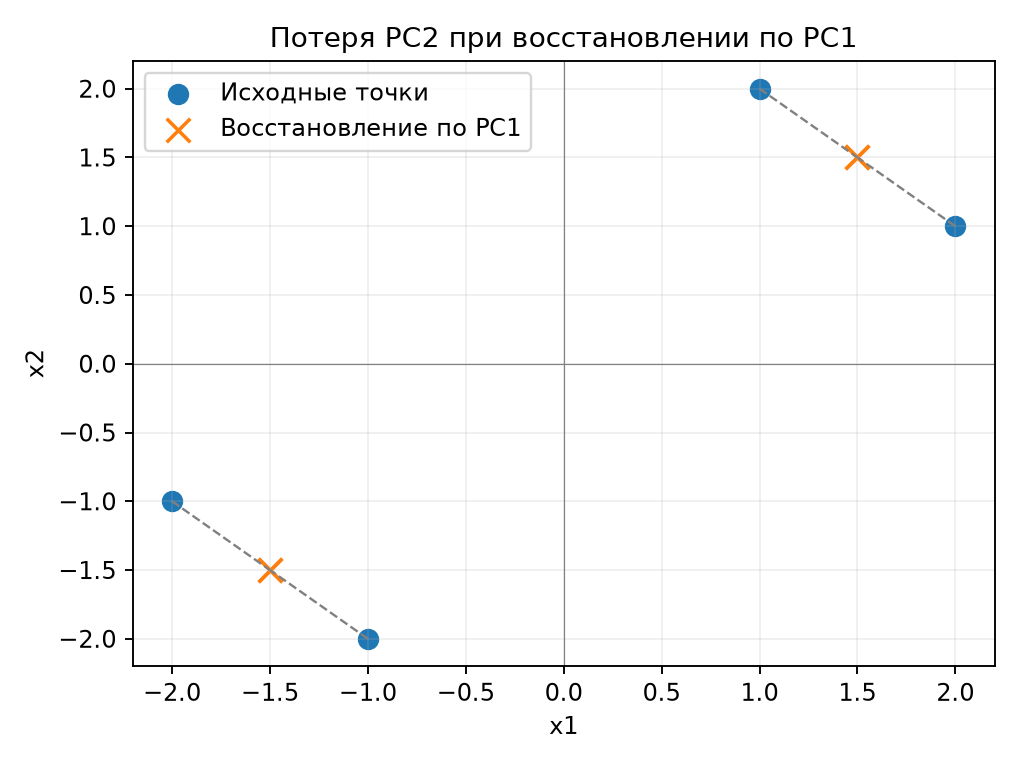

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import sklearn
print('Python:',sys.version.split()[0],'; sklearn:',sklearn.__version__)

X_small=np.array([[2.,1.],[1.,2.],[-1.,-2.],[-2.,-1.]])
mean_small=X_small.mean(axis=0)
X_c=X_small-mean_small
Sigma=X_c.T@X_c/(len(X_c)-1)
eigvals,eigvecs=np.linalg.eigh(Sigma)
order=np.argsort(eigvals)[::-1];eigvals=eigvals[order];eigvecs=eigvecs[:,order]
w1=np.array([1.,1.])/np.sqrt(2);w2=np.array([1.,-1.])/np.sqrt(2)
W=np.column_stack([w1,w2])
manual_scores=X_c@W
manual_rec=np.outer(manual_scores[:,0],w1)+mean_small
manual_rmse=float(np.sqrt(np.mean((X_small-manual_rec)**2)))
U,S,Vt=np.linalg.svd(X_c,full_matrices=False)
pca_small=PCA(n_components=1).fit(X_small)
sk_scores=pca_small.transform(X_small)
sk_rec=pca_small.inverse_transform(sk_scores)
print('Среднее:',mean_small,'; центрированная матрица:\n',X_c)
print('Выборочная ковариация Σ:\n',Sigma)
print('Собственные значения:',eigvals,'; доли:',eigvals/eigvals.sum())
print('Собственные оси NumPy (столбцы, знак условен):\n',eigvecs)
print('Ручные оси w1, w2 (столбцы):\n',W)
print('Сингулярные значения:',S,'; S²/(n−1):',S**2/(len(X_small)-1))
manual_table=pd.DataFrame({'point':range(1,5),'x1':X_small[:,0],'x2':X_small[:,1],
                           'score_PC1':manual_scores[:,0],'score_PC2':manual_scores[:,1],
                           'recovered_x1_PC1':manual_rec[:,0],'recovered_x2_PC1':manual_rec[:,1]})
print('Проекции и восстановление каждой точки:\n',manual_table.round(4).to_string(index=False))
print('Ручная доля PC1:',eigvals[0]/eigvals.sum(),'; RMSE одной PC:',manual_rmse)
assert np.allclose(Sigma,np.array([[10,8],[8,10]])/3)
assert np.allclose(eigvals,[6,2/3]) and np.isclose(eigvals[0]/eigvals.sum(),.9)
assert np.allclose(eigvals,S**2/(len(X_small)-1))
assert np.allclose(np.abs(eigvecs.T@W),np.eye(2),atol=1e-10)
assert np.isclose(manual_rmse,.5) and np.allclose(manual_rec,sk_rec)
assert np.allclose(np.abs(sk_scores[:,0]),np.abs(manual_scores[:,0]))
print('ASSERT PASS: Σ, λ, 90%, SVD, оси с точностью до знака, проекции и RMSE=0.5')
manual_table.to_csv('18_small_manual.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(6,4.5))
ax.scatter(X_small[:,0],X_small[:,1],s=65,label='Исходные точки')
ax.scatter(manual_rec[:,0],manual_rec[:,1],marker='x',s=100,label='Восстановление по PC1')
for i in range(len(X_small)):
    ax.plot([X_small[i,0],manual_rec[i,0]],[X_small[i,1],manual_rec[i,1]],'--',lw=1,color='gray')
ax.axhline(0,c='gray',lw=.5);ax.axvline(0,c='gray',lw=.5)
ax.set(xlabel='x1',ylabel='x2',title='Потеря PC2 при восстановлении по PC1');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig('18_small_reconstruction.png',dpi=170)
display(Image(filename='18_small_reconstruction.png'));plt.close(fig)


**Самостоятельно:** выпишите $w_1$ с точностью до знака; объясните, почему все данные, восстановленные по одной PC, лежат на прямой. Что теряется при удалении PC2?

## 2. Wine: 13 исходных измерений и масштабирование без утечек (25–42 мин)
Используйте встроенный набор `sklearn.datasets.load_wine` (178 объектов, 13 признаков). Истинные метки `wine.target` не участвуют в построении PCA и K-means; они могут использоваться **только для отдельной последующей проверки**, если преподаватель разрешит. Случайно отложите 20% объектов. Все параметры масштабирования — только по train.

Wine: (178, 13) train/test: (142, 13) (36, 13)
Масштабирование рассчитано только по train; пример средних z: [-0.  0. -0.  0. -0.]
Минимальное k для 95% train-дисперсии: 10 ; накопленная доля: 0.9619


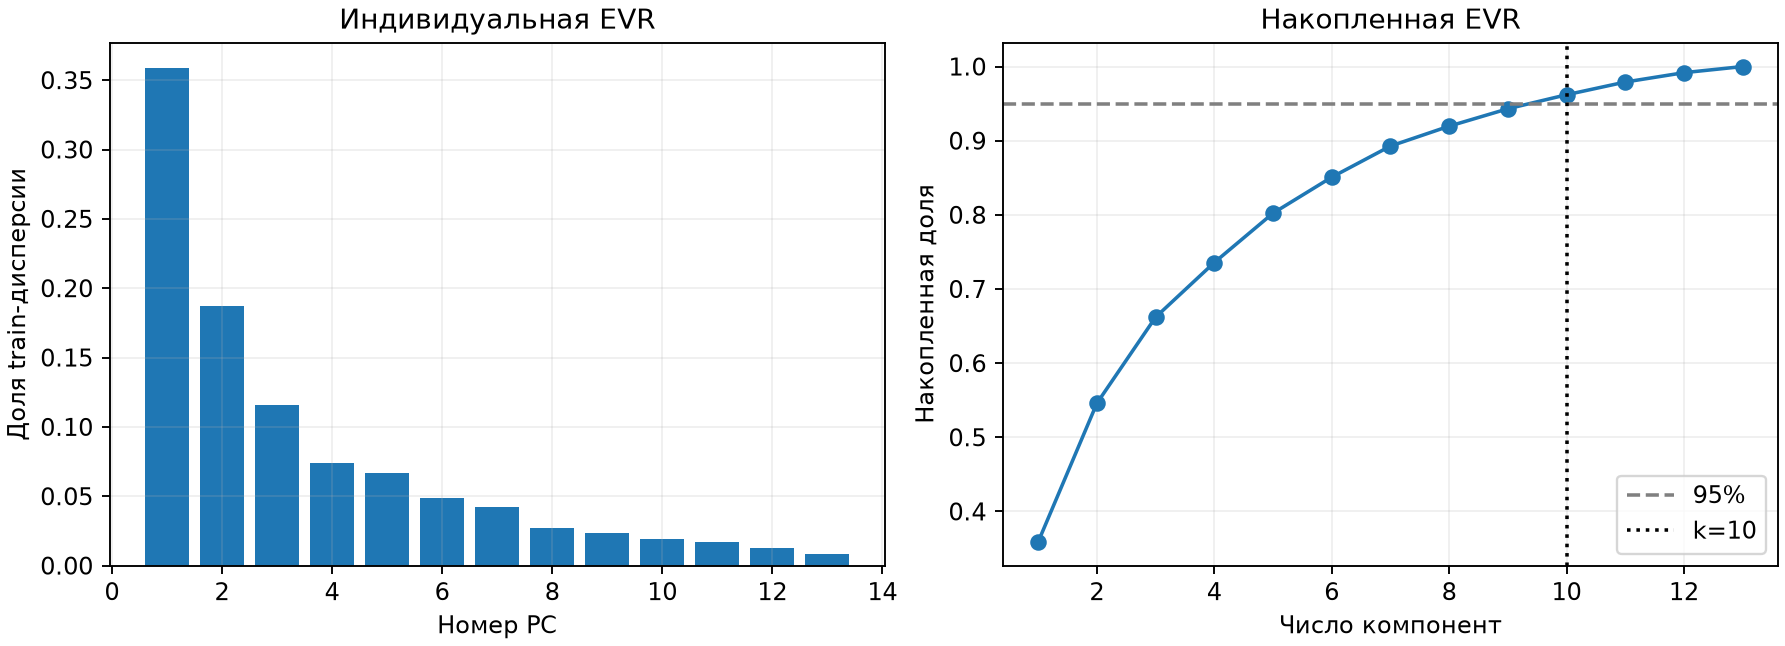

In [2]:
wine=load_wine(as_frame=True)
X=wine.data.copy()  # target не читается и не участвует ни в одном fit/выборе.
idx_train,idx_test=train_test_split(np.arange(len(X)),test_size=.20,random_state=42,shuffle=True)
X_train=X.iloc[idx_train].copy();X_test=X.iloc[idx_test].copy()
sc=StandardScaler().fit(X_train)
Z_train=sc.transform(X_train);Z_test=sc.transform(X_test)
assert X.shape==(178,13) and Z_train.shape==(142,13) and Z_test.shape==(36,13)
assert np.isfinite(Z_train).all() and np.isfinite(Z_test).all()
assert np.allclose(Z_train.mean(axis=0),0,atol=1e-10)
print('Wine:',X.shape,'train/test:',Z_train.shape,Z_test.shape)
print('Масштабирование рассчитано только по train; пример средних z:',Z_train.mean(axis=0).round(8)[:5])
pca_all=PCA().fit(Z_train)
ratio=pca_all.explained_variance_ratio_;cum=np.cumsum(ratio)
k95=int(np.searchsorted(cum,.95)+1)
print('Минимальное k для 95% train-дисперсии:',k95,'; накопленная доля:',round(float(cum[k95-1]),4))
evr_table=pd.DataFrame({'PC':np.arange(1,len(ratio)+1),'individual_EVR':ratio,'cumulative_EVR':cum})
evr_table.to_csv('18_wine_evr.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(10.5,3.8),constrained_layout=True)
axs[0].bar(np.arange(1,len(ratio)+1),ratio);axs[0].set(xlabel='Номер PC',ylabel='Доля train-дисперсии',title='Индивидуальная EVR')
axs[1].plot(np.arange(1,len(cum)+1),cum,marker='o');axs[1].axhline(.95,ls='--',c='gray',label='95%')
axs[1].axvline(k95,ls=':',c='black',label=f'k={k95}')
axs[1].set(xlabel='Число компонент',ylabel='Накопленная доля',title='Накопленная EVR');axs[1].legend()
for a in axs:a.grid(alpha=.2)
fig.savefig('18_wine_evr.png',dpi=170)
display(Image(filename='18_wine_evr.png'));plt.close(fig)


## 3. PCA(2) и PCA(95%): удержанная дисперсия и ошибка восстановления (42–59 мин)
Порог `0.95` выбирает минимальное число компонент, объясняющее не менее 95% **обучающей** дисперсии. Реконструкцию измеряйте на `test` в **стандартизованных** координатах, чтобы признаки не перетягивали ошибку единицами измерения.

In [3]:
pca2=PCA(n_components=2).fit(Z_train)
pca95=PCA(n_components=.95).fit(Z_train)
T2=pca2.transform(Z_train);T95=pca95.transform(Z_train)
T2_test=pca2.transform(Z_test);T95_test=pca95.transform(Z_test)
rec2=pca2.inverse_transform(T2_test);rec95=pca95.inverse_transform(T95_test)
rmse2=float(np.sqrt(np.mean((Z_test-rec2)**2)))
rmse95=float(np.sqrt(np.mean((Z_test-rec95)**2)))
summary=pd.DataFrame([
    {'method':'PCA 2PC','k':T2.shape[1],'train_explained_variance':float(pca2.explained_variance_ratio_.sum()),'test_RMSE_scaled':rmse2},
    {'method':'PCA 95%','k':T95.shape[1],'train_explained_variance':float(pca95.explained_variance_ratio_.sum()),'test_RMSE_scaled':rmse95}])
print('Восстановление Wine на независимом test, RMSE в стандартизованных координатах:\n',summary.round(4).to_string(index=False))
assert T95.shape[1]==k95 and rmse95<=rmse2+1e-10
s=np.linalg.svd(Z_train-Z_train.mean(axis=0),full_matrices=False,compute_uv=False)
assert np.allclose(s**2/(len(Z_train)-1),pca_all.explained_variance_)
print('ASSERT PASS: SVD train и спектр PCA совпадают; 95% выбирает минимальное k')
summary.to_csv('18_wine_pca_summary.csv',index=False,encoding='utf-8-sig')


Восстановление Wine на независимом test, RMSE в стандартизованных координатах:
  method  k  train_explained_variance  test_RMSE_scaled
PCA 2PC  2                    0.5459            0.5873
PCA 95% 10                    0.9619            0.1988
ASSERT PASS: SVD train и спектр PCA совпадают; 95% выбирает минимальное k


## 4. Как PCA влияет на кластеризацию? (59–78 мин)
Одни и те же объекты делим K-means на 3 группы до и после PCA. **ARI** сравнивает полученные разбиения и не зависит от номеров кластеров. Значения Silhouette в 13D и 2D отражают **разные геометрические пространства**, поэтому они не являются прямым доказательством «качество улучшилось».

Одинаковые 142 объекта train и K=3; ARI сравнивает метки, Silhouette — разные пространства:
      space  n_features  silhouette_in_own_space  ARI_vs_13D
13D scaled          13                   0.2748       1.000
    PCA 2D           2                   0.5477       0.957
   PCA 95%          10                   0.2877       1.000
ARI разбиений PCA 2D и PCA 95%: 0.957


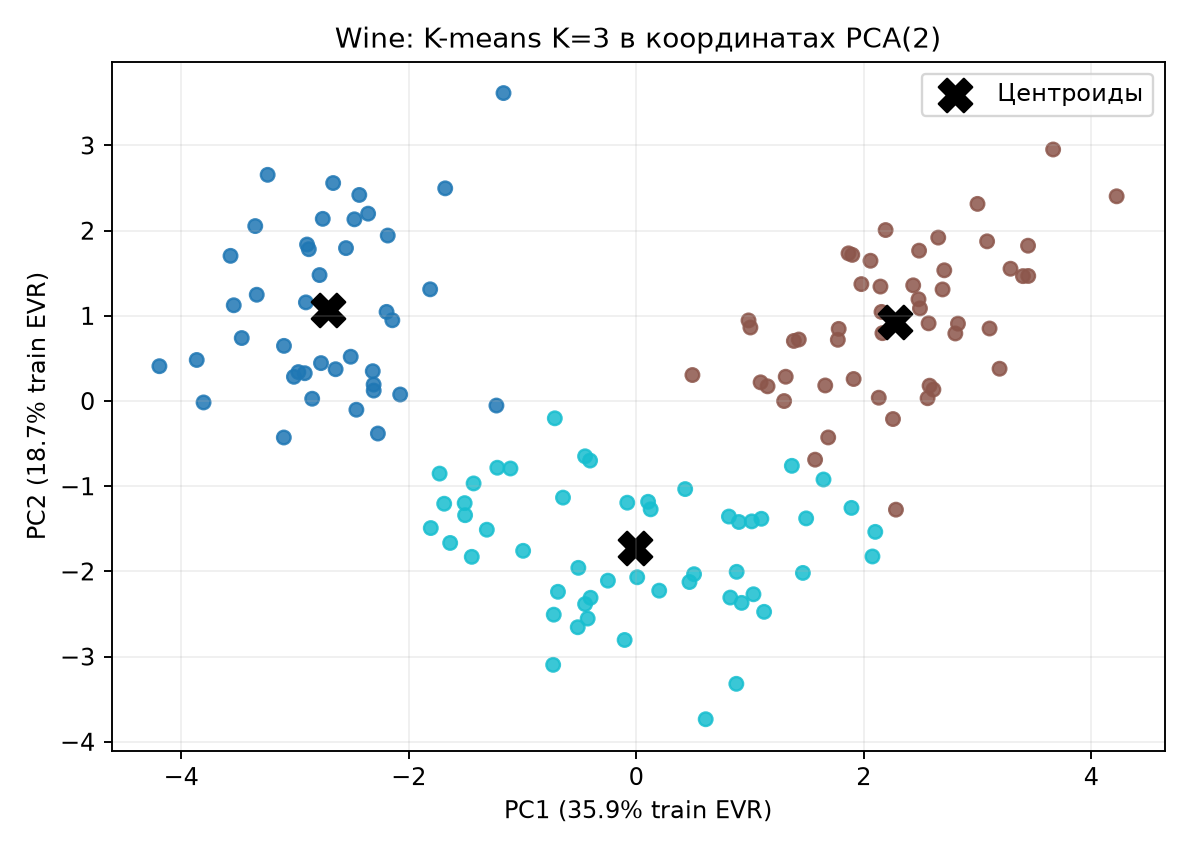

Самостоятельное сравнение при K=2 и 4 (те же объекты; Silhouette по своей шкале):
  K  ARI_13D_vs_2PC  ARI_13D_vs_95pct  silhouette_13D  silhouette_2PC  silhouette_95pct
 2          1.0000            1.0000          0.2649          0.4773            0.2756
 4          0.7038            0.8252          0.2522          0.4934            0.2752


In [4]:
K=3
spaces={'13D scaled':Z_train,'PCA 2D':T2,'PCA 95%':T95}
models={name:KMeans(n_clusters=K,n_init=10,random_state=42).fit(data) for name,data in spaces.items()}
base_labels=models['13D scaled'].labels_
comp=pd.DataFrame([{'space':name,'n_features':data.shape[1],
                    'silhouette_in_own_space':float(silhouette_score(data,models[name].labels_)),
                    'ARI_vs_13D':float(adjusted_rand_score(base_labels,models[name].labels_))}
                   for name,data in spaces.items()])
print('Одинаковые 142 объекта train и K=3; ARI сравнивает метки, Silhouette — разные пространства:\n',comp.round(4).to_string(index=False))
print('ARI разбиений PCA 2D и PCA 95%:',round(float(adjusted_rand_score(models['PCA 2D'].labels_,models['PCA 95%'].labels_)),4))
comp.to_csv('18_wine_cluster_comparison.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(T2[:,0],T2[:,1],c=models['PCA 2D'].labels_,s=33,cmap='tab10',alpha=.85)
ax.scatter(models['PCA 2D'].cluster_centers_[:,0],models['PCA 2D'].cluster_centers_[:,1],marker='X',s=200,c='black',label='Центроиды')
ax.set(xlabel=f'PC1 ({pca2.explained_variance_ratio_[0]:.1%} train EVR)',
       ylabel=f'PC2 ({pca2.explained_variance_ratio_[1]:.1%} train EVR)',
       title='Wine: K-means K=3 в координатах PCA(2)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig('18_wine_pc_scatter.png',dpi=170)
display(Image(filename='18_wine_pc_scatter.png'));plt.close(fig)

extra=[]
for k in [2,4]:
    labs={name:KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(data) for name,data in spaces.items()}
    extra.append({'K':k,'ARI_13D_vs_2PC':float(adjusted_rand_score(labs['13D scaled'],labs['PCA 2D'])),
                  'ARI_13D_vs_95pct':float(adjusted_rand_score(labs['13D scaled'],labs['PCA 95%'])),
                  'silhouette_13D':float(silhouette_score(Z_train,labs['13D scaled'])),
                  'silhouette_2PC':float(silhouette_score(T2,labs['PCA 2D'])),
                  'silhouette_95pct':float(silhouette_score(T95,labs['PCA 95%']))})
extra_k=pd.DataFrame(extra)
print('Самостоятельное сравнение при K=2 и 4 (те же объекты; Silhouette по своей шкале):\n',extra_k.round(4).to_string(index=False))
extra_k.to_csv('18_wine_k2_k4.csv',index=False,encoding='utf-8-sig')


**Самостоятельно:** повторите K-means при `K=2` и `K=4`, назовите, какие сравнения правомерны. Объясните, почему ортогональный поворот без уменьшения числа компонент сохраняет евклидовы расстояния, а обрезка до 2PC — нет.

## 5. Возвращение к сквозному кейсу заказов (78–90 мин)
По трём доступным при создании заказа признакам оцените PCA(2) и различие разбиений K-means **только на ранних 80% заказов**. Поля `actual_minutes`, `late` и `order_id` исключены из пространства признаков. Не переносите обученный PCA с Wine на заказы — распределения и смысл признаков не совпадают.

In [5]:
source=Path('orders_dirty.csv')
assert source.exists(),'Нужен основной источник orders_dirty.csv из предыдущих практик'
assert Path('data_dictionary.csv').exists(),'Нужен data_dictionary.csv'
raw_orders=pd.read_csv(source,encoding='utf-8-sig')
FEATURES=['distance_km','queue_size','promised_minutes']
assert {'order_id','created_at',*FEATURES}.issubset(raw_orders.columns)
print('Заказы: исходный размер',raw_orders.shape,'; полные повторы',int(raw_orders.duplicated().sum()))
orders=raw_orders.drop_duplicates().copy()
orders['created_at']=pd.to_datetime(orders.created_at,errors='coerce')
assert orders.order_id.notna().all() and orders.order_id.is_unique and orders.created_at.notna().all()
for col in FEATURES:
    source_col=orders[col].astype(str).str.replace(',','.',regex=False) if col=='distance_km' else orders[col]
    orders[col]=pd.to_numeric(source_col,errors='coerce').replace([np.inf,-np.inf],np.nan)
    orders.loc[orders[col]<0,col]=np.nan
    if col=='promised_minutes':orders.loc[orders[col]<=0,col]=np.nan
orders=orders.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
cut=int(len(orders)*.8)
dev=orders.iloc[:cut].copy();holdout=orders.iloc[cut:].copy()
assert set(dev.order_id).isdisjoint(set(holdout.order_id)) and dev.created_at.max()<=holdout.created_at.min()
assert {'order_id','actual_minutes','late'}.isdisjoint(FEATURES)
from sklearn.impute import SimpleImputer
imp=SimpleImputer(strategy='median',keep_empty_features=True).fit(dev[FEATURES])
order_sc=StandardScaler().fit(imp.transform(dev[FEATURES]))
Z_order=order_sc.transform(imp.transform(dev[FEATURES]))
assert np.isfinite(Z_order).all() and np.allclose(Z_order.mean(axis=0),0,atol=1e-10)
pca_order=PCA(n_components=2).fit(Z_order)
T_order=pca_order.transform(Z_order)
k_o_full=KMeans(n_clusters=3,n_init=10,random_state=42).fit_predict(Z_order)
k_o_2=KMeans(n_clusters=3,n_init=10,random_state=42).fit_predict(T_order)
order_ari=float(adjusted_rand_score(k_o_full,k_o_2))
order_evr=pca_order.explained_variance_ratio_
print('Основной источник:',source.name,'; после удаления повторов:',len(orders),'; dev/holdout:',len(dev),len(holdout))
print('Три ранних признака:',FEATURES,'; запрещены order_id, actual_minutes, late')
print('Пропуски после приведения:',dev[FEATURES].isna().sum().to_dict())
print('Параметры только dev — медианы:',imp.statistics_.round(3),'; средние:',order_sc.mean_.round(3),'; шкалы:',order_sc.scale_.round(3))
print('PCA заказов: EVR PC1/PC2:',order_evr.round(4),'; сумма:',round(float(order_evr.sum()),4))
print('ARI K-means K=3 на 3D и PCA(2), только dev:',round(order_ari,4))
order_summary=pd.DataFrame([{'source':'orders_dirty.csv','n_raw':len(raw_orders),'n_clean':len(orders),
                             'n_dev':len(dev),'n_holdout':len(holdout),'feature_1':FEATURES[0],
                             'feature_2':FEATURES[1],'feature_3':FEATURES[2],
                             'EVR_PC1':float(order_evr[0]),'EVR_PC2':float(order_evr[1]),
                             'EVR_2PC':float(order_evr.sum()),'ARI_3D_vs_2PC':order_ari}])
order_summary.to_csv('18_orders_pca_summary.csv',index=False,encoding='utf-8-sig')
result=dev[['order_id','created_at']].copy()
result['cluster_3d']=k_o_full;result['cluster_pca2']=k_o_2
result.to_csv('18_orders_cluster_comparison.csv',index=False,encoding='utf-8-sig')
print('Holdout не участвовал в fit scaler, PCA или K-means и не применялся для выбора компонент.')


Заказы: исходный размер (600, 10) ; полные повторы 1
Основной источник: orders_dirty.csv ; после удаления повторов: 599 ; dev/holdout: 479 120
Три ранних признака: ['distance_km', 'queue_size', 'promised_minutes'] ; запрещены order_id, actual_minutes, late
Пропуски после приведения: {'distance_km': 1, 'queue_size': 1, 'promised_minutes': 0}
Параметры только dev — медианы: [ 8.95  9.   51.  ] ; средние: [ 9.17  10.021 50.952] ; шкалы: [ 5.256  6.447 14.059]
PCA заказов: EVR PC1/PC2: [0.6465 0.3246] ; сумма: 0.9711
ARI K-means K=3 на 3D и PCA(2), только dev: 0.9946
Holdout не участвовал в fit scaler, PCA или K-means и не применялся для выбора компонент.


### Что сдавать
1. Отчёт 2–4 страницы: матрица ковариации и её спектр для 4×2, проверка SVD, таблица Wine «2PC/95%», график долей и 2D-разброса, таблица ARI сравнения кластеризаций.
2. `18_student.ipynb` (Restart & Run All), CSV при наличии; описание связи с кейсом заказов.
3. Самостоятельно: объясните роль стандартизации, знаковую неоднозначность компонент и почему 95% дисперсии **не** означает 95% качества ML-модели.

**Контроль:** отличается ли PCA от отбора двух исходных столбцов? Почему `pca.fit` нельзя делать на test? Какие потери при восстановлении по 2PC?

## Ответы на самостоятельные вопросы ноутбука

### Вопрос из раздела 1: ось PC1 и потеря PC2

Первая главная ось малого примера — $w_1=(1,1)/\sqrt{2}$ с точностью до общего знака. Проекции четырёх точек на неё равны примерно 2,1213; 2,1213; −2,1213; −2,1213. Восстановление только по PC1 даёт (1,5; 1,5), (1,5; 1,5), (−1,5; −1,5), (−1,5; −1,5). Все эти точки лежат на прямой $x_1=x_2$, потому что сохраняется только координата вдоль одной оси. Удаление PC2 стирает различие между первой и второй точками, а также между третьей и четвёртой. Её доля дисперсии — 10%; RMSE восстановления в исходных координатах малого примера — 0,5.

### Вопрос из раздела 4: K=2 и K=4, допустимые сравнения

Сравнения выполнены на одних и тех же 142 объектах train Wine при одинаковом K в каждой строке:

| K | ARI 13D и 2PC | ARI 13D и PCA 95% | Silhouette 13D | Silhouette 2PC | Silhouette 95% |
|---:|---:|---:|---:|---:|---:|
| 2 | 1,0000 | 1,0000 | 0,2649 | 0,4773 | 0,2756 |
| 4 | 0,7038 | 0,8252 | 0,2522 | 0,4934 | 0,2752 |

ARI правомерно сравнивает **разбиения одних и тех же объектов** и не зависит от перестановки номеров групп; для ясной оценки эффекта PCA фиксируется K. Silhouette вычислен внутри каждого собственного пространства и не доказывает улучшение качества при сравнении 13D с 2D. При K=3 ARI 13D против 2PC = 0,9570, а против PCA 95% = 1,0000. Если сохранить все 13 ортонормальных PC, PCA только поворачивает стандартизованное пространство и евклидовы расстояния сохраняются. При обрезке до 2PC удаляются координаты PC3–PC13, поэтому расстояния и иногда состав кластеров меняются.

### Вопрос из заключительного раздела: стандартизация, знак и 95% дисперсии

Стандартизация Wine, рассчитанная только на train, приводит признаки с разными единицами к сопоставимому масштабу: без неё PCA и K-means могли бы в первую очередь отражать признаки с большим численным разбросом. Собственный вектор можно умножить на −1 без изменения его оси, объяснённой дисперсии, расстояний или реконструкции при согласованной смене знака координат. Для Wine 2PC удержали 54,59% train-дисперсии и дали test RMSE 0,5873; порог 95% потребовал 10 PC, удержал 96,19% и дал test RMSE 0,1988 в **стандартизованных координатах**. Объяснённая дисперсия измеряет вариацию X, а не точность последующей модели: даже малая по дисперсии компонента может быть важна для решения другой задачи. Истинные классы Wine не использовались при fit PCA или K-means.

### Сквозной кейс заказов

На 479 ранних заказах из 599 очищенных 2PC объяснили 97,11% дисперсии трёх стандартизованных признаков: PC1 — 64,65%, PC2 — 32,46%. ARI K-means при K=3 в исходных 3D и после PCA(2) составил 0,9946. Последние 120 заказов не участвовали в обучении scaler, PCA и K-means или выборе числа компонент. Номера групп не являются оценкой качества доставки; 2D-вид скрывает потерянное третье направление.
